# News Headlines and Market Direction

Can the day's top 25 world-news headlines predict whether the Dow Jones closes up or down? Each row is one trading day: 25 headlines and a label (1 = up day, 0 = down day). The notebook cleans the text, builds TF-IDF features and compares four classifiers against a majority-class baseline.

Evaluation respects time. Days are kept in order: cross-validation uses expanding windows (`TimeSeriesSplit`), and the final test set is the last 20% of days. Feature selection sits inside the pipeline, so it is refitted on each training fold and never sees validation or test labels.

In [1]:
import re

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import seaborn as sns
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.naive_bayes import MultinomialNB
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC

nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)

SEED = 2022
sns.set_theme(style="whitegrid")

## Data

In [2]:
ds = pd.read_csv("data/train.csv").sort_values("Id").reset_index(drop=True)
headlines = [c for c in ds.columns if c.startswith("Headline")]
ds[headlines] = ds[headlines].fillna("")
print(ds.shape, "|", len(headlines), "headlines per day")
ds["Closing Status"].value_counts(normalize=True)

(1690, 27) | 25 headlines per day


Closing Status
1    0.533728
0    0.466272
Name: proportion, dtype: float64

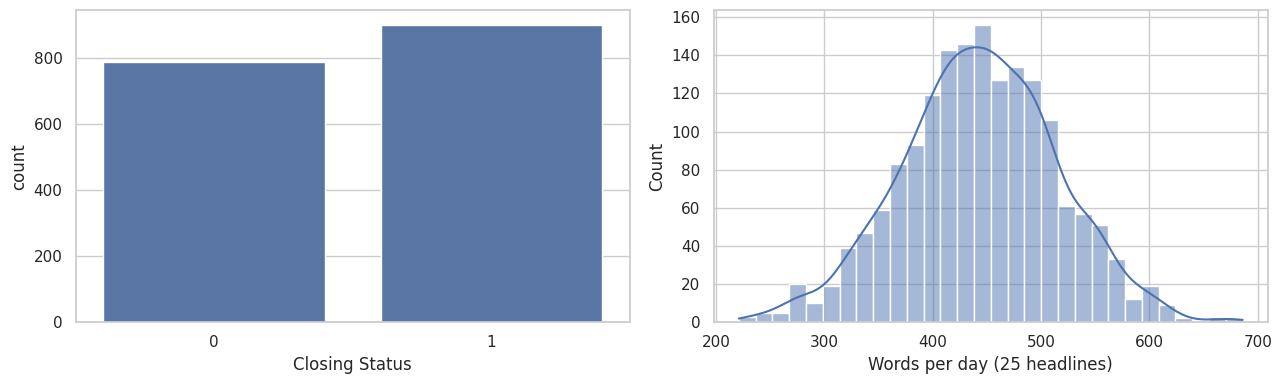

In [3]:
words_per_day = ds[headlines].apply(lambda row: sum(len(h.split()) for h in row), axis=1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=ds, x="Closing Status", ax=axes[0])
sns.histplot(words_per_day, kde=True, ax=axes[1])
axes[1].set_xlabel("Words per day (25 headlines)")
plt.tight_layout()
plt.show()

The classes are close to balanced (about 53% up days), so a classifier has to beat roughly 53% accuracy to be worth anything.

## Text cleaning

In [4]:
STOP = set(stopwords.words("english")) | {"u", "say", "says", "year", "new"}
stemmer = PorterStemmer()
lemma = WordNetLemmatizer()

CONTRACTIONS = [(r"n't", " not"), (r"'s", ""), (r"'ve", " have"), (r"'re", " are"),
                (r"'d", " would"), (r"'ll", " will")]


def clean(text, lemmatize=True, stem=False):
    """Lower-case, expand contractions, strip links, mentions, hashtags, digits and
    punctuation, drop stop words and one-letter tokens, then lemmatise and/or stem."""
    text = text.lower()
    text = re.sub(r"^b['\"]", "", text)           # byte-string prefixes in the raw data
    for pattern, repl in CONTRACTIONS:
        text = re.sub(pattern, repl, text)
    text = re.sub(r"http\S+|@\w+|#\w+", " ", text)
    text = re.sub(r"[^a-z]", " ", text)
    tokens = [w for w in text.split() if w not in STOP and len(w) > 1]
    if lemmatize:
        tokens = [lemma.lemmatize(w) for w in tokens]
    if stem:
        tokens = [stemmer.stem(w) for w in tokens]
    return " ".join(tokens)


print(ds.loc[0, "Headline1"])
print(clean(ds.loc[0, "Headline1"]))

Milan court convicts Berlusconi of tax evasion, gives 4-year sentence


milan court convict berlusconi tax evasion give sentence


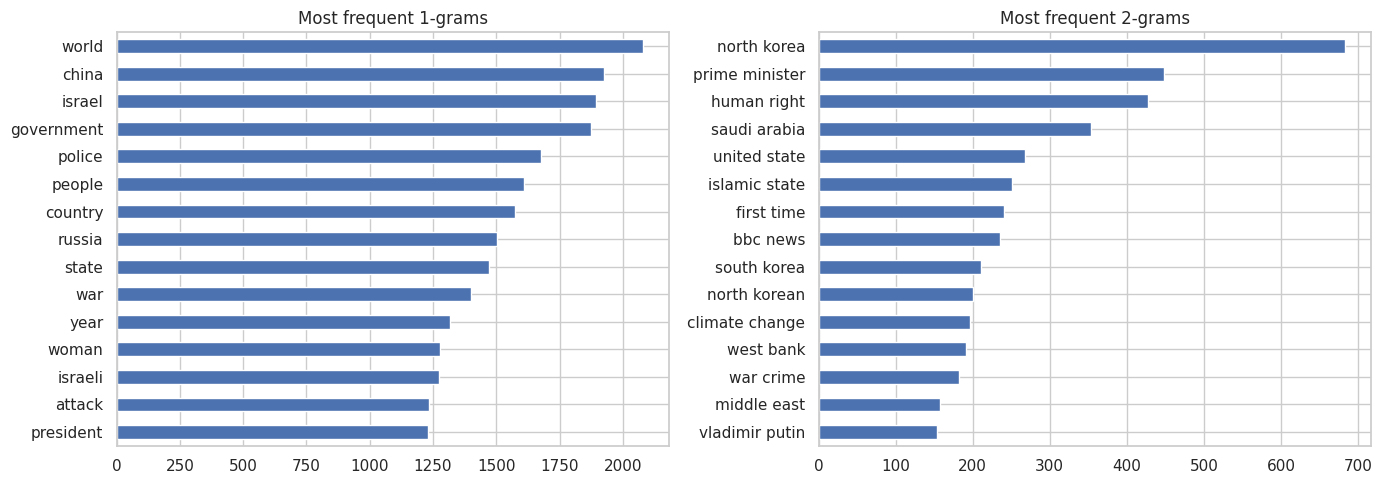

In [5]:
ds["text"] = ds[headlines].apply(lambda row: " ".join(clean(h) for h in row), axis=1)
y = ds["Closing Status"].to_numpy()

def top_ngrams(texts, n, k=15):
    vec = CountVectorizer(ngram_range=(n, n)).fit(texts)
    counts = np.asarray(vec.transform(texts).sum(axis=0)).ravel()
    order = counts.argsort()[::-1][:k]
    return pd.Series(counts[order], index=vec.get_feature_names_out()[order])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for n, ax in zip([1, 2], axes):
    top_ngrams(ds["text"], n).plot.barh(ax=ax, title=f"Most frequent {n}-grams")
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

## Models

Each model is a pipeline: TF-IDF on 1- and 2-grams, the 300 terms most associated with the label (ANOVA F-test), then the classifier.

In [6]:
def text_pipeline(clf):
    return make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2), min_df=10, max_df=0.8, strip_accents="unicode"),
        SelectKBest(f_classif, k=300),
        clf,
    )

models = {
    "Majority class": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": text_pipeline(LogisticRegression(max_iter=1000, random_state=SEED)),
    "Naive Bayes": text_pipeline(MultinomialNB()),
    "Linear SVM": text_pipeline(LinearSVC(random_state=SEED)),
    "MLP": text_pipeline(MLPClassifier(hidden_layer_sizes=(80, 60, 40), early_stopping=True,
                                       random_state=SEED, max_iter=300)),
}

split = int(len(ds) * 0.8)
X_train, X_test = ds["text"].iloc[:split], ds["text"].iloc[split:]
y_train, y_test = y[:split], y[split:]
print(f"train: {len(X_train)} days, test: {len(X_test)} days")

train: 1352 days, test: 338 days


### Time-series cross-validation on the training period

In [7]:
cv = TimeSeriesSplit(n_splits=5)
rows = {}
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=["accuracy", "roc_auc"])
    rows[name] = {"CV accuracy": scores["test_accuracy"].mean(),
                  "CV accuracy sd": scores["test_accuracy"].std(),
                  "CV ROC AUC": scores["test_roc_auc"].mean()}
cv_table = pd.DataFrame(rows).T
cv_table.round(3)

,CV accuracy,CV accuracy sd,CV ROC AUC
Majority class,0.547,0.022,0.500
Logistic regression,0.515,0.016,0.488
Naive Bayes,0.523,0.014,0.489
Linear SVM,0.507,0.036,0.490
MLP,0.504,0.027,0.470


### Final test on the last 20% of days

In [8]:
test_rows = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    score = model.decision_function(X_test) if hasattr(model, "decision_function") else model.predict_proba(X_test)[:, 1]
    test_rows[name] = {"Test accuracy": accuracy_score(y_test, pred),
                       "Test ROC AUC": roc_auc_score(y_test, score)}
results = cv_table.join(pd.DataFrame(test_rows).T)
results.round(3)

,CV accuracy,CV accuracy sd,CV ROC AUC,Test accuracy,Test ROC AUC
Majority class,0.547,0.022,0.500,0.509,0.500
Logistic regression,0.515,0.016,0.488,0.497,0.526
Naive Bayes,0.523,0.014,0.489,0.512,0.540
Linear SVM,0.507,0.036,0.490,0.500,0.534
MLP,0.504,0.027,0.470,0.533,0.534


In [9]:
best = results.drop(index="Majority class")["CV ROC AUC"].idxmax()
print("Best model by CV ROC AUC:", best)
print(classification_report(y_test, models[best].predict(X_test), digits=3))

Best model by CV ROC AUC: Linear SVM
              precision    recall  f1-score   support

           0      0.487     0.337     0.399       166
           1      0.507     0.657     0.572       172

    accuracy                          0.500       338
   macro avg      0.497     0.497     0.485       338
weighted avg      0.497     0.500     0.487       338



In [10]:
# Sanity checks: all models ran and the scores are probabilities in range.
assert results.shape[0] == 5
assert results.drop(columns="CV accuracy sd").apply(lambda s: s.between(0, 1).all()).all()

## How much would leakage inflate the score?

A common mistake is to fit TF-IDF and the feature selector on all labelled days, then cross-validate only the classifier with shuffled folds. The selector has then already seen every validation label, and shuffling lets the model train on days after the ones it predicts. The cell below measures that setup with the same logistic regression.

In [11]:
from sklearn.model_selection import KFold, cross_val_score

leaky_X = SelectKBest(f_classif, k=300).fit_transform(
    TfidfVectorizer(ngram_range=(1, 2), min_df=10, max_df=0.8).fit_transform(X_train), y_train)
leaky = cross_val_score(LogisticRegression(max_iter=1000, random_state=SEED), leaky_X, y_train,
                        cv=KFold(5, shuffle=True, random_state=SEED), scoring="accuracy")
honest = results.loc["Logistic regression", "CV accuracy"]
print(f"leaky CV accuracy:  {leaky.mean():.3f}")
print(f"honest CV accuracy: {honest:.3f}")

leaky CV accuracy:  0.611
honest CV accuracy: 0.515


## Conclusion

- **No signal under honest evaluation.** With days kept in order and feature selection refitted inside every fold, no classifier beats the majority-class baseline in cross-validation (accuracy 0.50-0.52 against 0.55; ROC AUC 0.47-0.49). On the final test period the best ROC AUC is 0.54, within noise of chance.
- **Leakage manufactures a result.** The same logistic regression scores 0.611 when the selector sees all labels and folds are shuffled, against 0.515 when done properly: ten points of accuracy that would not survive deployment.
- **Takeaway:** a day's world headlines, as bag-of-words features, do not predict the Dow Jones direction in this data, which is what weak-form market efficiency would lead one to expect. Any text-based market signal should be tested with time-ordered validation and all fitting inside the folds.
